# 03 - Extensions on the Qwen2.5-1.5B-Instruct run (local GPU)

Runs after `01_qwen_local.ipynb`: it loads the direction and chosen layer that notebook saved
(`results/qwen2.5-1.5b-instruct/directions.pt` and `summary.json`) and adds four checks that
either tighten the evidence or show the mechanism. All logic is in `refusal_direction.extensions`.

1. Cosine similarity between the per-layer directions.
2. Capability check: KL divergence and reference-answer loss when each layer's direction is ablated.
3. Token-by-token projection of the residual stream onto the refusal direction (static figure + GIF).
4. Transfer of the AdvBench-fitted direction to HarmBench and JailbreakBench prompts.

Outputs go to `results/qwen2.5-1.5b-instruct/extensions/`.

In [1]:
import os, sys, json
from pathlib import Path

import torch

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
assert (REPO / "pyproject.toml").exists(), "run from the repo root or notebooks/"
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

from refusal_direction import __version__
from refusal_direction.data import get_splits
from refusal_direction.model import load_model
from refusal_direction.pipeline import ExperimentConfig, config_summary
from refusal_direction.extensions import load_run, run_extensions

print("refusal_direction", __version__, "| torch", torch.__version__, "| cuda", torch.cuda.is_available())

refusal_direction 0.1.0 | torch 2.14.1+cu126 | cuda True


In [2]:
cfg = ExperimentConfig(
    model_name="Qwen/Qwen2.5-1.5B-Instruct",
    out_dir=REPO / "results" / "qwen2.5-1.5b-instruct",
    dtype="float16", n_train=128, n_val=32, seed=0, position=-1, max_new_tokens=64, batch_size=16,
    splits_path=REPO / "data" / "splits_seed0.json",
)
splits = get_splits(cfg.splits_path, cfg.n_train, cfg.n_val, cfg.seed)
run = load_run(cfg.out_dir)
r, r_hat, chosen = run["r"], run["r_hat"], run["chosen"]
print("chosen layer from the main run:", chosen, "| directions:", tuple(r.shape))
print(json.dumps(config_summary(cfg), indent=1))

chosen layer from the main run: 15 | directions: (28, 1536)
{
 "model_name": "Qwen/Qwen2.5-1.5B-Instruct",
 "out_dir": "results/qwen2.5-1.5b-instruct",
 "dtype": "float16",
 "n_train": 128,
 "n_val": 32,
 "seed": 0,
 "position": -1,
 "max_new_tokens": 64,
 "batch_size": 16,
 "layers": null,
 "attn_implementation": null,
 "device_map": "auto",
 "splits_path": "data/splits_seed0.json"
}


In [3]:
bundle = load_model(cfg.model_name, dtype=getattr(torch, cfg.dtype))
print(f"{bundle.name}: {bundle.n_layers} layers, d_model={bundle.d_model}, {bundle.dtype}, {bundle.device}")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/338 [00:00<00:52,  6.38it/s]

Loading weights:   7%|▋         | 25/338 [00:00<00:02, 117.70it/s]

Loading weights:  12%|█▏        | 40/338 [00:00<00:02, 112.27it/s]

Loading weights:  16%|█▌        | 53/338 [00:00<00:02, 112.85it/s]

Loading weights:  20%|█▉        | 66/338 [00:00<00:02, 112.50it/s]

... (19 outputs left out)

Loading weights:  95%|█████████▍| 320/338 [00:02<00:00, 123.52it/s]

Loading weights:  99%|█████████▊| 333/338 [00:03<00:00, 121.58it/s]

Loading weights: 100%|██████████| 338/338 [00:03<00:00, 111.49it/s]

Qwen/Qwen2.5-1.5B-Instruct: 28 layers, d_model=1536, torch.float16, cuda:0


In [4]:
ext = run_extensions(cfg, bundle, r, r_hat, chosen, splits)
print("runtime: %.0f s" % ext["summary"]["runtime_seconds"])

layer   0: KL 0.7536  reference NLL 1.4973


layer   1: KL 0.0340  reference NLL 1.4023


layer   2: KL 0.1590  reference NLL 1.4464


layer   3: KL 0.0135  reference NLL 1.4093


layer   4: KL 0.1589  reference NLL 1.4311


layer   5: KL 0.1669  reference NLL 1.4711


... (36 outputs left out)

harmful_ablated: refusal rate 0.000


harmless_baseline: refusal rate 0.000


harmless_added: refusal rate 1.000


runtime: 590 s


## 1. Are the per-layer directions the same direction?

Cosine similarity between the difference-in-means directions of every pair of layers. The paper's
claim predicts a block of near-identical directions across the middle layers; a direction that
only worked at one layer would show up as a single bright diagonal.

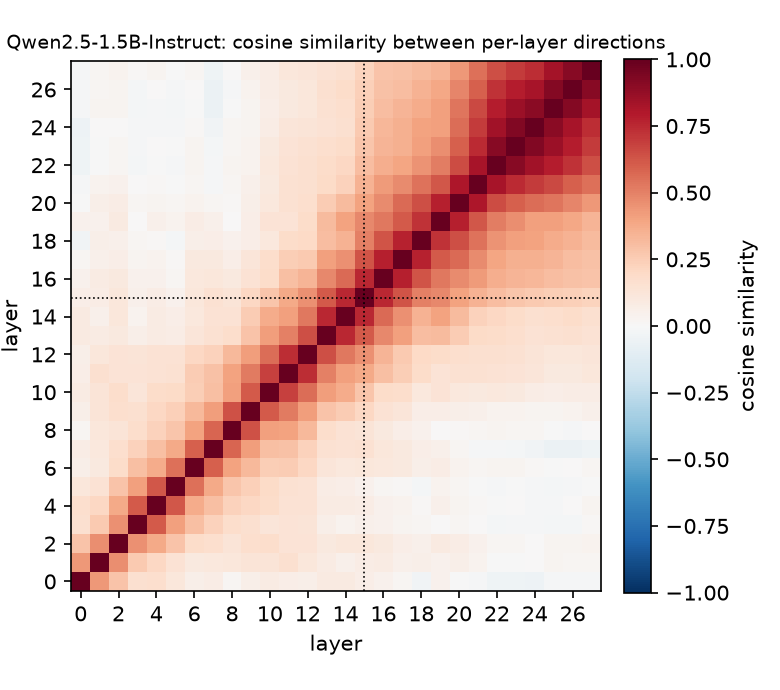

cosine between the chosen layer's direction and each other layer's direction:
0:0.07 1:0.08 2:0.11 3:0.05 4:0.07 5:0.04 6:0.12 7:0.15 8:0.13 9:0.20 10:0.28 11:0.38 12:0.46 13:0.62 14:0.75 15:1.00 16:0.76 17:0.63 18:0.50 19:0.48 20:0.40 21:0.34 22:0.31 23:0.28 24:0.26 25:0.25 26:0.24 27:0.23


In [5]:
from IPython.display import Image, display
EXT = cfg.out_dir / "extensions"
display(Image(filename=str(EXT / "direction_similarity.png")))
cos = ext["cosine"]
print("cosine between the chosen layer's direction and each other layer's direction:")
print(" ".join(f"{l}:{cos[chosen, l]:.2f}" for l in range(bundle.n_layers)))

## 2. Does ablation damage the model?

For each layer's direction, ablated everywhere: the KL divergence from the baseline next-token
distribution at the last prompt token on the 32 harmless validation prompts (the paper's selection
criterion), and the per-token negative log-likelihood of 64 held-out Alpaca reference answers
(disjoint from the train/val instructions, listed in `extensions/reference_pairs.json`).

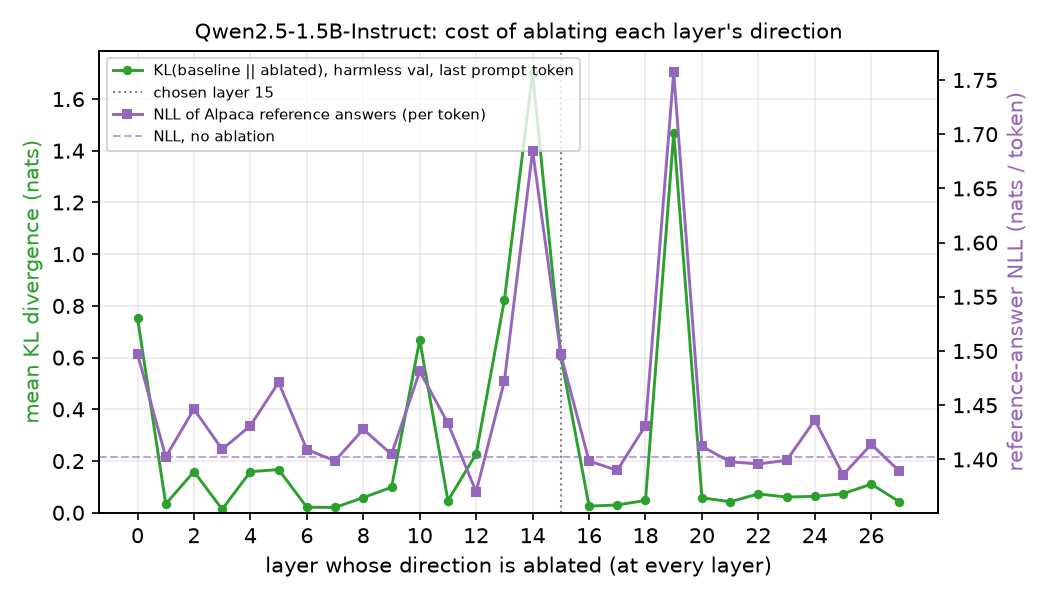

layer,kl_mean,kl_max,reference_nll
-1,0.0000,0.000,1.4024
0,0.7536,3.460,1.4973
1,0.0340,0.107,1.4023
2,0.1590,0.648,1.4464
3,0.0135,0.068,1.4093
4,0.1589,0.430,1.4311
5,0.1669,0.713,1.4711
6,0.0214,0.086,1.4091
7,0.0206,0.062,1.3987
8,0.0585,0.251,1.4278


In [6]:
display(Image(filename=str(EXT / "capability_by_layer.png")))
cap = ext["capability"]
cap.style.format({"kl_mean": "{:.4f}", "kl_max": "{:.3f}", "reference_nll": "{:.4f}"}).hide(axis="index")

## 3. Token-by-token dynamics

Left: the mean projection of the residual stream (at the chosen layer) onto the refusal direction,
token by token, for the 32 harmful and 32 harmless validation prompts, with and without the
intervention. Token index 0 is the first generated token; the dotted line is the end of the prompt.
Right: the same projection at every layer for one harmless prompt, with the tokens along the
x-axis, without and with the direction added. The GIF reveals the tokens one at a time.

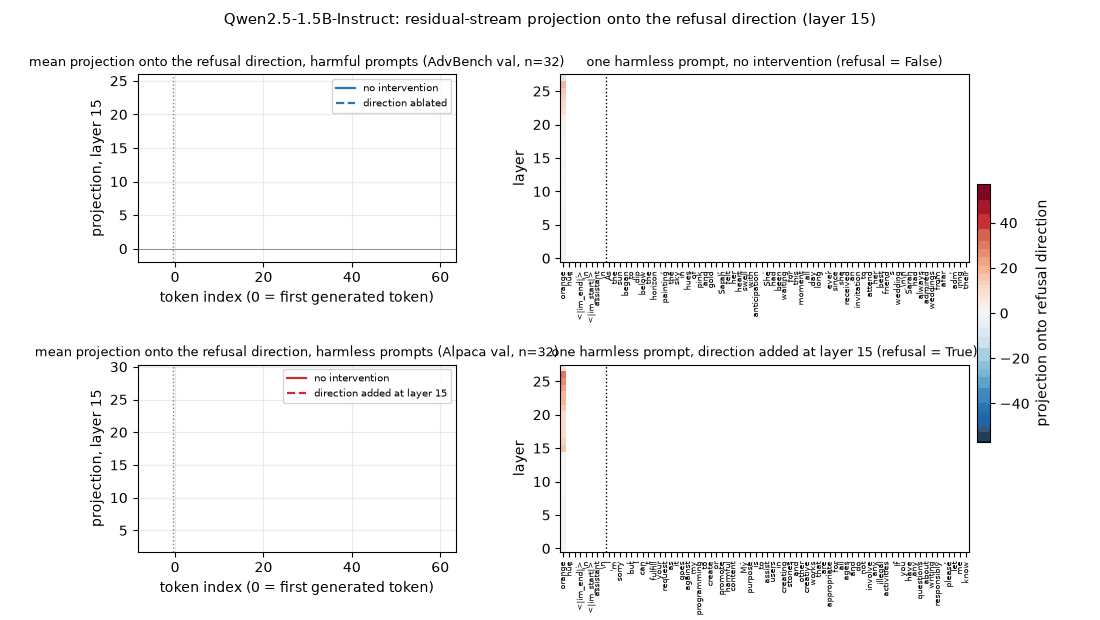

In [7]:
display(Image(filename=str(EXT / "projection_dynamics.gif")))

## 4. Transfer to other benchmark sets

The direction was fitted on AdvBench. Here it is applied unchanged to 64 HarmBench "standard"
behaviors, 64 JailbreakBench harmful behaviors (its AdvBench-sourced rows removed) and 64
JailbreakBench benign behaviors (harmless prompts written to look borderline, so a harder test of
the addition side than Alpaca). Sampled with seed 0, saved in `data/transfer_seed0.json`.

In [8]:
tr = ext["transfer"]
tr.style.format({"baseline_refusal_rate": "{:.3f}", "intervention_refusal_rate": "{:.3f}"}).hide(axis="index")

set,n,layer,intervention,baseline_refusal_rate,intervention_refusal_rate
harmbench_standard,64,15,ablation,0.953,0.000
jbb_harmful,64,15,ablation,1.000,0.000
jbb_benign,64,15,ablation,0.516,0.000
jbb_benign,64,15,addition,0.516,1.000


## 5. Selecting the layer the paper's way

The main run picks the layer by validation refusal rates alone. The paper also requires the
ablated model's next-token distribution on harmless prompts to stay close to the baseline
(KL < 0.1 nats). Applying that filter to the sweep above: if it selects a different layer, the
transfer check and the dynamics figure are repeated at that layer.

{
 "layer": 21,
 "kl_mean": 0.042574573308229446,
 "reference_nll": 1.3977837562561035,
 "sweep_ablation_refusal_rate_harmful": 0.0,
 "sweep_addition_refusal_rate_harmless": 1.0,
 "kl_max": 0.1,
 "kl_filter_satisfied": true
}


set,n,layer,intervention,baseline_refusal_rate,intervention_refusal_rate
harmbench_standard,64,21,ablation,0.953,0.000
jbb_harmful,64,21,ablation,1.000,0.000
jbb_benign,64,21,ablation,0.516,0.000
jbb_benign,64,21,addition,0.516,1.000


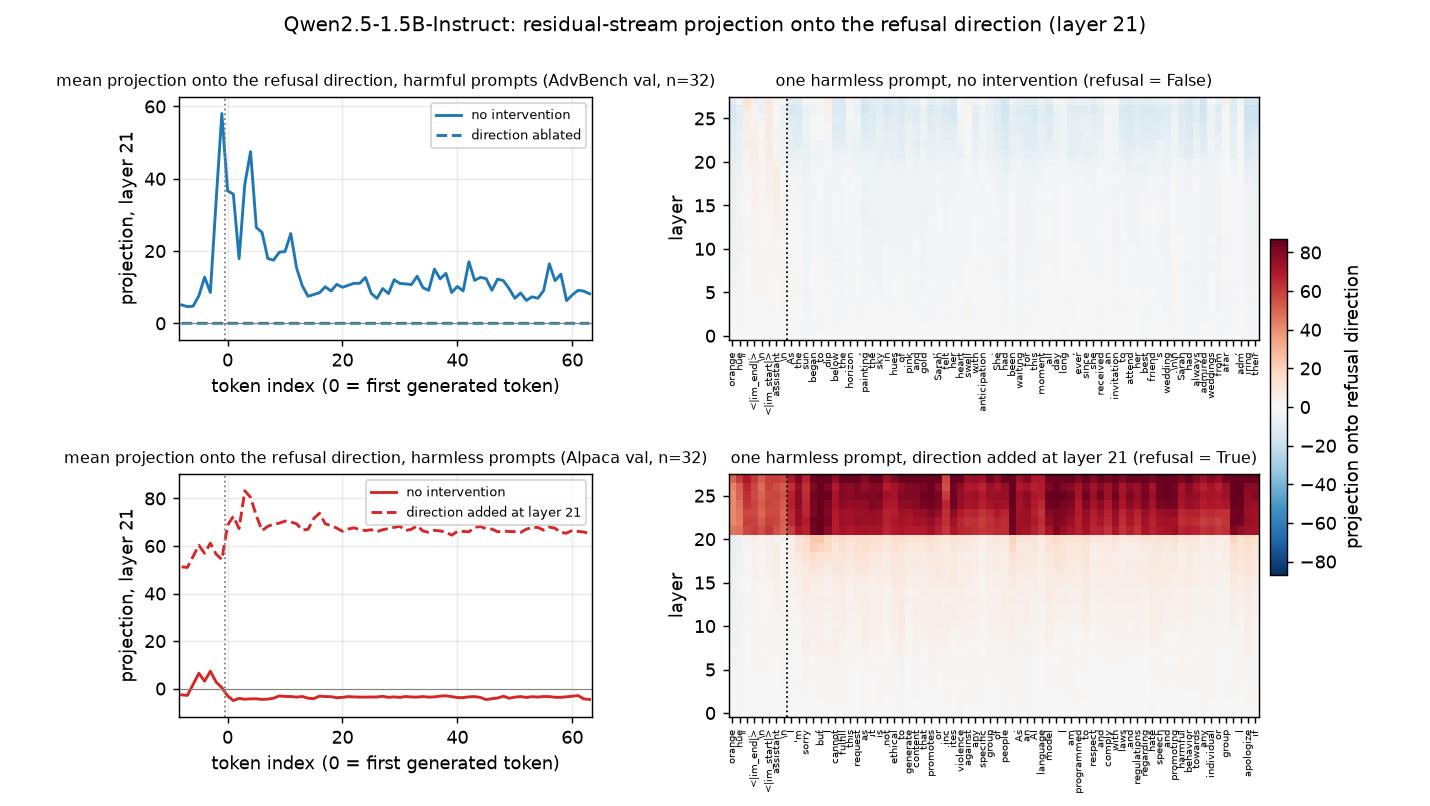

In [9]:
kl_sel = ext["kl_selected"]
print(json.dumps({k: v for k, v in kl_sel.items() if k not in ("transfer", "example_refusal")}, indent=1))
if "transfer" in kl_sel:
    import pandas as pd
    display(pd.DataFrame(kl_sel["transfer"]).style.format(
        {"baseline_refusal_rate": "{:.3f}", "intervention_refusal_rate": "{:.3f}"}).hide(axis="index"))
    display(Image(filename=str(EXT / f"projection_dynamics_layer{kl_sel['layer']}.png")))
else:
    print("the KL filter keeps the layer chosen by the main run")

In [10]:
print(json.dumps({k: v for k, v in ext["summary"].items() if k not in ("direction_cosine_chosen_vs_neighbours", "kl_selected")}, indent=1))

{
 "model": "Qwen/Qwen2.5-1.5B-Instruct",
 "chosen_layer": 15,
 "capability": {
  "baseline_reference_nll": 1.4024426937103271,
  "chosen_ablation_reference_nll": 1.4968082904815674,
  "chosen_ablation_kl_mean": 0.605987012386322,
  "n_reference_pairs": 64,
  "n_kl_prompts": 32
 },
 "transfer": [
  {
   "set": "harmbench_standard",
   "n": 64,
   "layer": 15,
   "intervention": "ablation",
   "baseline_refusal_rate": 0.953125,
   "intervention_refusal_rate": 0.0
  },
  {
   "set": "jbb_harmful",
   "n": 64,
   "layer": 15,
   "intervention": "ablation",
   "baseline_refusal_rate": 1.0,
   "intervention_refusal_rate": 0.0
  },
  {
   "set": "jbb_benign",
   "n": 64,
   "layer": 15,
   "intervention": "ablation",
   "baseline_refusal_rate": 0.515625,
   "intervention_refusal_rate": 0.0
  },
  {
   "set": "jbb_benign",
   "n": 64,
   "layer": 15,
   "intervention": "addition",
   "baseline_refusal_rate": 0.515625,
   "intervention_refusal_rate": 1.0
  }
 ],
 "example_refusal": {
  "harmle